<a href="https://colab.research.google.com/github/sawantshravani519-del/CodeAlpha_CarPricePrediction/blob/main/CodeAlpha_CarPricePrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("My Car Price Prediction project has started!")
print("Python is ready.")

My Car Price Prediction project has started!
Python is ready.


In [ ]:

import pandas as pd

column_names = [
    "symboling", "normalized_losses", "make", "fuel_type",
    "aspiration", "num_of_doors", "body_style", "drive_wheels",
    "engine_location", "wheel_base", "length", "width", "height",
    "curb_weight", "engine_type", "num_of_cylinders",
    "engine_size", "fuel_system", "bore", "stroke",
    "compression_ratio", "horsepower", "peak_rpm", "city_mpg",
    "highway_mpg", "price"
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"

df = pd.read_csv(url, names=column_names, na_values="?")

print("Car data loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Car data loaded successfully!
Rows and columns: (205, 26)


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [ ]:
# Clean the car data

df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["engine_size"] = pd.to_numeric(
    df["engine_size"], errors="coerce"
)
df["horsepower"] = pd.to_numeric(
    df["horsepower"], errors="coerce"
)

df = df.dropna(subset=["price"]).copy()

print("Data cleaning completed!")
print("Number of cars:", len(df))
print("Missing values in price:", df["price"].isna().sum())

display(df[["make", "engine_size", "horsepower", "price"]].head())

Data cleaning completed!
Number of cars: 201
Missing values in price: 0


,make,engine_size,horsepower,price
0,alfa-romero,130,111.0,13495.0
1,alfa-romero,130,111.0,16500.0
2,alfa-romero,152,154.0,16500.0
3,audi,109,102.0,13950.0
4,audi,136,115.0,17450.0


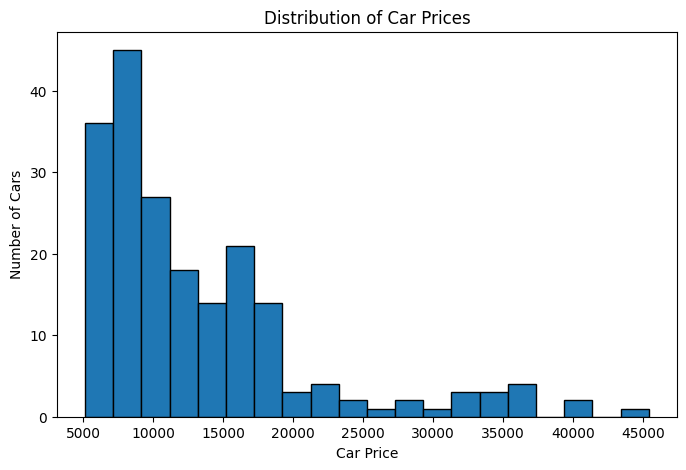

In [ ]:
# Show the distribution of car prices

plt.figure(figsize=(8, 5))
plt.hist(df["price"], bins=20, edgecolor="black")

plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Number of Cars")

plt.show()

In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of rows and columns:")
print(df.shape)

Missing values in each column:
symboling             0
normalized_losses    37
make                  0
fuel_type             0
aspiration            0
num_of_doors          2
body_style            0
drive_wheels          0
engine_location       0
wheel_base            0
length                0
width                 0
height                0
curb_weight           0
engine_type           0
num_of_cylinders      0
engine_size           0
fuel_system           0
bore                  4
stroke                4
compression_ratio     0
horsepower            2
peak_rpm              2
city_mpg              0
highway_mpg           0
price                 0
dtype: int64

Number of rows and columns:
(201, 26)


In [ ]:
# Convert car information into numbers where possible

for col in df.columns:
    if col not in ["make", "fuel_type", "aspiration",
                   "num_of_doors", "body_style", "drive_wheels",
                   "engine_location", "engine_type",
                   "num_of_cylinders", "fuel_system"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Keep rows that have a known car price
df = df.dropna(subset=["price"]).copy()

print("Data is ready for the next stage!")
print("Number of cars:", len(df))
print("Number of columns:", len(df.columns))

Data is ready for the next stage!
Number of cars: 201
Number of columns: 26


In [ ]:
# Separate car information from car prices

X = df.drop(columns=["price"])
y = df["price"]

print("Car information is separated!")
print("Input data shape:", X.shape)
print("Price data shape:", y.shape)

Car information is separated!
Input data shape: (201, 25)
Price data shape: (201,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data split completed!")
print("Training cars:", len(X_train))
print("Testing cars:", len(X_test))

Data split completed!
Training cars: 160
Testing cars: 41


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Machine-learning tools are ready!")

Machine-learning tools are ready!


In [ ]:
# Identify number columns and text columns

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Number columns:", len(numeric_features))
print("Text columns:", len(categorical_features))
print("Text columns include:", categorical_features)

Number columns: 15
Text columns: 10
Text columns include: ['make', 'fuel_type', 'aspiration', 'num_of_doors', 'body_style', 'drive_wheels', 'engine_location', 'engine_type', 'num_of_cylinders', 'fuel_system']


In [ ]:
# Prepare number and text columns for machine learning

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Data processor is ready!")

Data processor is ready!


In [ ]:
# Build the car price prediction model

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

print("Car price prediction model is built!")

Car price prediction model is built!


In [ ]:
# Train the model using the training data

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
# Predict prices for the test cars

y_pred = model.predict(X_test)

print("Predictions completed!")
print("First 5 actual prices:")
print(y_test.head().tolist())

print("\nFirst 5 predicted prices:")
print(y_pred[:5].round(2).tolist())

Predictions completed!
First 5 actual prices:
[8249.0, 41315.0, 6855.0, 9258.0, 11850.0]

First 5 predicted prices:
[7173.4, 31583.58, 6194.61, 8074.81, 13319.61]


In [ ]:
# Evaluate prediction accuracy

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

MODEL EVALUATION RESULTS
------------------------
Mean Absolute Error: 1824.2
Root Mean Squared Error: 2813.88
R2 Score: 0.935


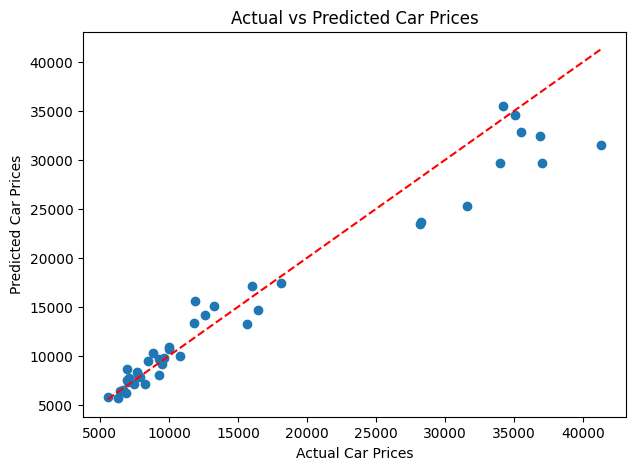

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Car Prices")
plt.ylabel("Predicted Car Prices")
plt.title("Actual vs Predicted Car Prices")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred.round(2)
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,8249.0,7173.40
1,41315.0,31583.58
2,6855.0,6194.61
3,9258.0,8074.81
4,11850.0,13319.61
5,5572.0,5824.05
6,35056.0,34547.27
7,9988.0,10918.67
8,15998.0,17182.10
9,35550.0,32840.64


,Feature,Importance
6,num__curb_weight,0.425610
7,num__engine_size,0.320697
11,num__horsepower,0.064452
14,num__highway_mpg,0.055433
4,num__width,0.029782
13,num__city_mpg,0.019697
2,num__wheel_base,0.011603
17,cat__make_bmw,0.009516
12,num__peak_rpm,0.007237
1,num__normalized_losses,0.007063


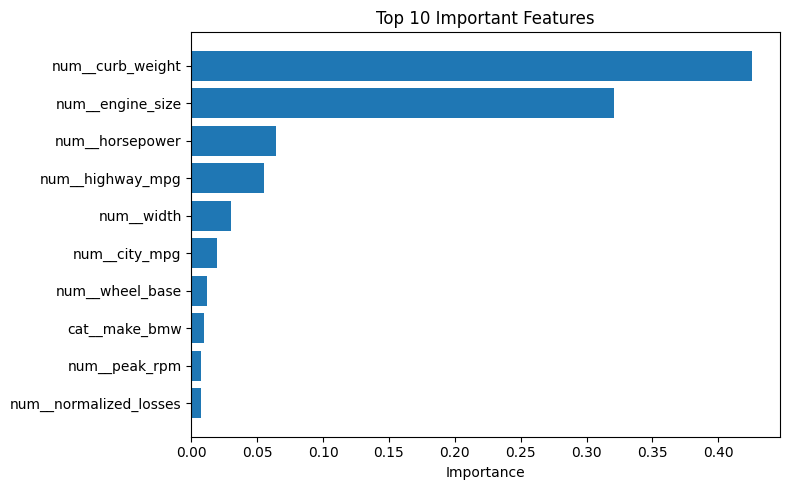

In [ ]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importance = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

plt.figure(figsize=(8, 5))
top_features = importance_df.head(10).sort_values("Importance")
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

print("Linear Regression MAE:",
      round(mean_absolute_error(y_test, linear_pred), 2))

print("Random Forest MAE:",
      round(mean_absolute_error(y_test, y_pred), 2))

Linear Regression MAE: 1972.15
Random Forest MAE: 1824.2


# Car Price Prediction using Machine Learning

CodeAlpha Data Science Internship — Task 3

My project will use machine learning to predict car prices.

Dataset: UCI Automobile dataset.

Conclusion

This project focused on predicting automobile prices using machine learning and the UCI Automobile dataset.

The dataset was cleaned, and missing values were handled. Exploratory data analysis was performed using a car-price histogram and an engine-size versus price scatter plot.

A Random Forest Regressor was trained using car features. Its performance was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score. A Linear Regression model was also trained for comparison.

- Random Forest MAE: [enter your result]
- Random Forest RMSE: [enter your result]
- Random Forest R²: [enter your result]
- Linear Regression MAE: [enter your result]

The results show how machine learning can estimate car prices from vehicle characteristics. Prediction accuracy depends on the dataset and the features available.

Project: Car Price Prediction

Internship: CodeAlpha Data Science Internship
Task: Task 3 — Car Price Prediction

Objective

Build a machine-learning model that predicts automobile prices from vehicle specifications.

Dataset

UCI Automobile dataset, containing vehicle details such as make, engine size, horsepower, and price.

Technologies Used

- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Google Colab

Methods

- Data cleaning and preprocessing
- Exploratory data analysis
- Random Forest Regression
- Linear Regression
- Model evaluation using MAE, RMSE, and R²